# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Andi Winata
- NIM   : 241011400534
- Kelas : Reg B 

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [ ]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 34   # isi dengan 2 digit terakhir NIM Anda

In [ ]:
# ============ FUNGSI DARI MATERI ============

# 1. Fungsi Split Data
def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    n = len(X)
    n_test = int(n * test_size)
    idx = np.random.permutation(n)
    test_idx = idx[:n_test]
    train_idx = idx[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

# 2. Kelas Linear Regression (Normal Equation)
class LinearRegression:
    def __init__(self):
        self.coef_ = None
        self.intercept_ = None
    def fit(self, X, y):
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        theta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self
    def predict(self, X):
        return X @ self.coef_ + self.intercept_

# 3. Kelas Linear Regression Gradient Descent
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr = learning_rate
        self.n_iter = n_iterations
        self.coef_ = None
        self.intercept_ = None
        self.loss_history = []
    def fit(self, X, y):
        n, m = X.shape
        self.coef_ = np.zeros(m)
        self.intercept_ = 0.0
        self.loss_history = []
        for _ in range(self.n_iter):
            y_pred = X @ self.coef_ + self.intercept_
            err = y_pred - y
            dw = (2 / n) * X.T @ err
            db = (2 / n) * np.sum(err)
            self.coef_      -= self.lr * dw
            self.intercept_ -= self.lr * db
            self.loss_history.append(np.mean(err ** 2))
        return self
    def predict(self, X):
        return X @ self.coef_ + self.intercept_

# 4. Kelas Logistic Regression
class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.lr = learning_rate
        self.n_iter = n_iterations
        self.coef_ = None
        self.intercept_ = None
        self.loss_history = []
    def sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))
    def fit(self, X, y):
        n, m = X.shape
        self.coef_ = np.zeros(m)
        self.intercept_ = 0.0
        self.loss_history = []
        eps = 1e-15
        for _ in range(self.n_iter):
            y_hat = self.sigmoid(X @ self.coef_ + self.intercept_)
            err = y_hat - y
            dw = (1 / n) * X.T @ err
            db = (1 / n) * np.sum(err)
            self.coef_      -= self.lr * dw
            self.intercept_ -= self.lr * db
            p = np.clip(y_hat, eps, 1 - eps)
            self.loss_history.append(-np.mean(y*np.log(p) + (1-y)*np.log(1-p)))
        return self
    def predict_proba(self, X):
        return self.sigmoid(X @ self.coef_ + self.intercept_)
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

# 5. Fungsi Metrik Evaluasi
def mae(y, yp):   return np.mean(np.abs(y - yp))
def mse(y, yp):   return np.mean((y - yp) ** 2)
def rmse(y, yp):  return np.sqrt(mse(y, yp))
def r2_score(y, yp):
    ss_res = np.sum((y - yp) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    return 1 - ss_res / ss_tot

def accuracy_score(y, yp): return np.mean(y == yp)
def confusion_matrix(y, yp):
    tp = np.sum((y == 1) & (yp == 1))
    tn = np.sum((y == 0) & (yp == 0))
    fp = np.sum((y == 0) & (yp == 1))
    fn = np.sum((y == 1) & (yp == 0))
    return np.array([[tn, fp], [fn, tp]])
def precision_score(y, yp):
    cm = confusion_matrix(y, yp)
    return cm[1,1] / (cm[1,1] + cm[0,1]) if (cm[1,1] + cm[0,1]) else 0
def recall_score(y, yp):
    cm = confusion_matrix(y, yp)
    return cm[1,1] / (cm[1,1] + cm[1,0]) if (cm[1,1] + cm[1,0]) else 0
def f1_score(y, yp):
    p, r = precision_score(y, yp), recall_score(y, yp)
    return 2*p*r/(p+r) if (p+r) else 0
    # Salin fungsi train_test_split dari materi di sini

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3
Jumlah baris: 40


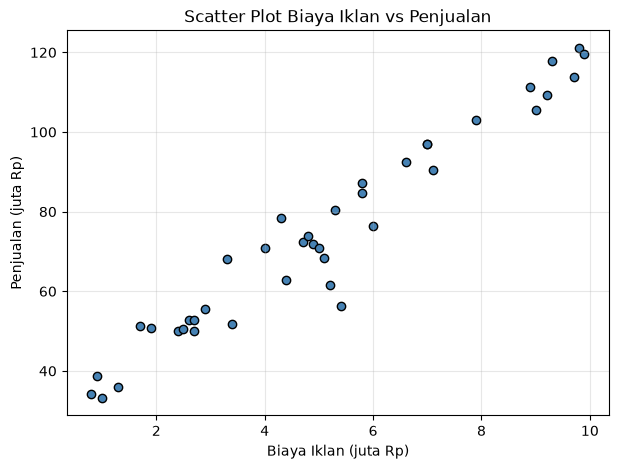

In [ ]:
# Jawaban A1
df = pd.read_csv("Ads_Data.csv")
print(df.head())
print("Jumlah baris:", len(df))

X = df[["BiayaIklan"]].values.astype(float)
y = df["Penjualan"].values.astype(float)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], y, color="steelblue", edgecolor="k")
plt.title("Scatter Plot Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(alpha=0.3)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [ ]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [ ]:
# Jawaban A3
lin_reg = LinearRegression().fit(X_train, y_train)
b0 = lin_reg.intercept_
b1 = lin_reg.coef_[0]

print(f"Intercept (b0) : {b0:.4f}")
print(f"Koefisien (b1) : {b1:.4f}")
print(f"Persamaan      : Penjualan = {b0:.4f} + {b1:.4f} * BiayaIklan")

Intercept (b0) : 27.7936
Koefisien (b1) : 9.1971
Persamaan      : Penjualan = 27.7936 + 9.1971 * BiayaIklan


**Jawaban A3 (interpretasi):**

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [ ]:
# Jawaban A4
def evaluate(name, y, yp):
    return {"Data": name,
            "MAE":  mae(y, yp),
            "MSE":  mse(y, yp),
            "RMSE": rmse(y, yp),
            "R2":   r2_score(y, yp)}

yp_tr = lin_reg.predict(X_train)
yp_te = lin_reg.predict(X_test)

hasil = pd.DataFrame([evaluate("Train", y_train, yp_tr),
                      evaluate("Test",  y_test,  yp_te)])
print(hasil.to_string(index=False, float_format="%.4f"))

 Data    MAE     MSE   RMSE     R2
Train 4.4865 38.3334 6.1914 0.9380
 Test 4.4396 27.0583 5.2018 0.9547


**Jawaban A4 (analisis):**

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

lr=0.001 | b0=   24.0151 | b1=    9.7734 | loss_akhir=4.1141e+01
lr= 0.02 | b0=   27.7936 | b1=    9.1971 | loss_akhir=3.8333e+01


C:\Users\Asus\AppData\Local\Temp\ipykernel_15788\1563218078.py:48: RuntimeWarning: overflow encountered in square
  self.loss_history.append(np.mean(err ** 2))
C:\python\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\python\Lib\site-packages\numpy\_core\fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
C:\Users\Asus\AppData\Local\Temp\ipykernel_15788\1563218078.py:47: RuntimeWarning: invalid value encountered in scalar subtract
  self.intercept_ -= self.lr * db


lr=  0.1 | b0=       nan | b1=       nan | loss_akhir=nan

Normal Equation : b0=27.7936 | b1=9.1971


C:\python\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


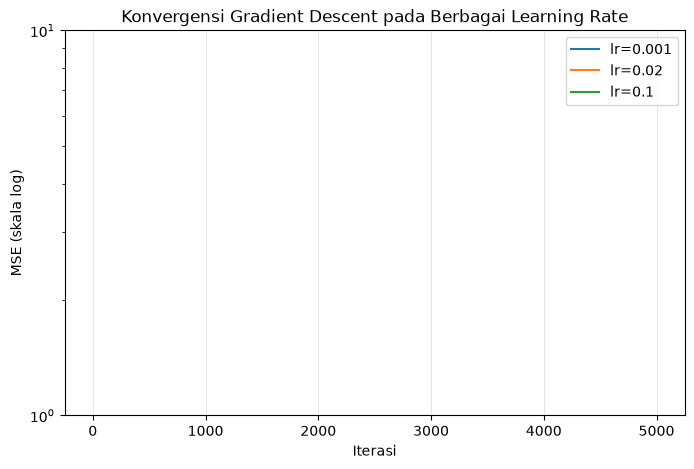

In [ ]:
# Jawaban A5
lrs = [0.001, 0.02, 0.1]
plt.figure(figsize=(8, 5))

for lr in lrs:
    gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    plt.plot(gd.loss_history, label=f"lr={lr}")
    print(f"lr={lr:>5} | b0={gd.intercept_:10.4f} | b1={gd.coef_[0]:10.4f} | "
          f"loss_akhir={gd.loss_history[-1]:.4e}")

print(f"\nNormal Equation : b0={lin_reg.intercept_:.4f} | b1={lin_reg.coef_[0]:.4f}")
plt.yscale("log")
plt.xlabel("Iterasi"); plt.ylabel("MSE (skala log)")
plt.title("Konvergensi Gradient Descent pada Berbagai Learning Rate")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Jawaban A5 (analisis):**

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

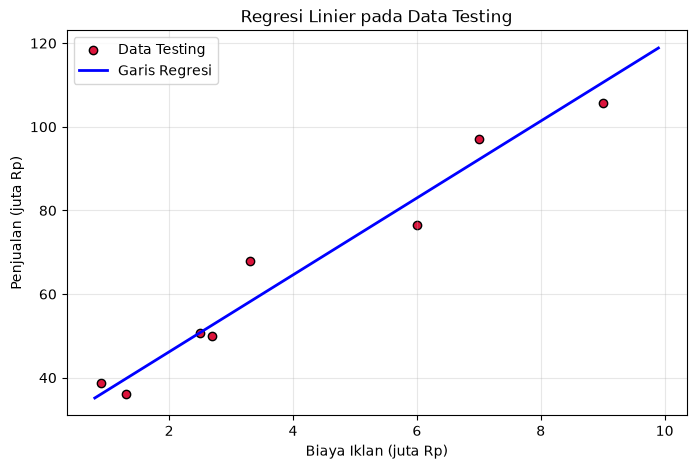

BiayaIklan=4.5 juta -> prediksi Penjualan = 69.18 juta Rp
BiayaIklan=7 juta -> prediksi Penjualan = 92.17 juta Rp
BiayaIklan=12 juta -> prediksi Penjualan = 138.16 juta Rp


In [ ]:
# Jawaban A6
plt.figure(figsize=(8, 5))
plt.scatter(X_test[:,0], y_test, color="crimson", label="Data Testing", edgecolor="k")
xs = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
plt.plot(xs, lin_reg.predict(xs), "b-", lw=2, label="Garis Regresi")
plt.xlabel("Biaya Iklan (juta Rp)"); plt.ylabel("Penjualan (juta Rp)")
plt.title("Regresi Linier pada Data Testing")
plt.legend(); plt.grid(alpha=0.3); plt.show()

for v in [4.5, 7, 12]:
    pred = lin_reg.predict(np.array([[v]]))[0]
    print(f"BiayaIklan={v} juta -> prediksi Penjualan = {pred:.2f} juta Rp")

**Jawaban A6 (analisis):**

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah Spam      : 25
Jumlah Bukan Spam: 35


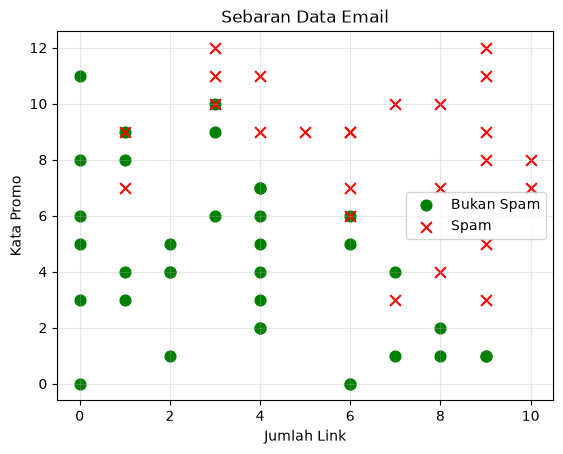

In [ ]:
# Jawaban B1
df = pd.read_csv("Email_Data.csv")
print(df.head())
print("\nJumlah Spam      :", (df["Spam"] == 1).sum())
print("Jumlah Bukan Spam:", (df["Spam"] == 0).sum())

X = df[["JumlahLink", "KataPromo"]].values.astype(float)
y = df["Spam"].values.astype(int)

for label, color, mark in [(0, "green", "o"), (1, "red", "x")]:
    m = y == label
    plt.scatter(X[m,0], X[m,1], c=color, marker=mark, s=60,
                label="Bukan Spam" if label==0 else "Spam")
plt.xlabel("Jumlah Link"); plt.ylabel("Kata Promo")
plt.title("Sebaran Data Email"); plt.legend(); plt.grid(alpha=0.3); plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Intercept (b0)  : -8.3285
Koef JumlahLink : 0.7155
Koef KataPromo  : 0.7076
Persamaan: z = -8.3285 + 0.7155*x1 + 0.7076*x2


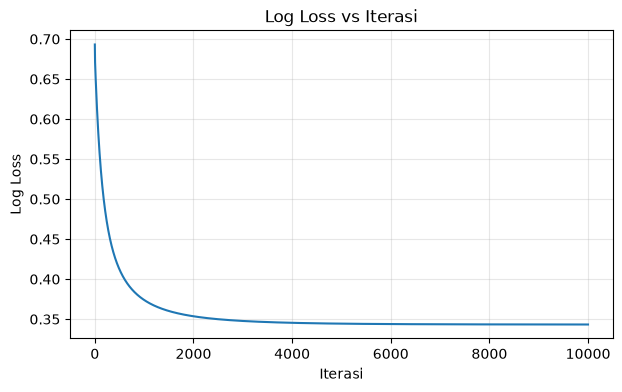

In [ ]:
# Jawaban B2
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE)

log_reg = LogisticRegression(learning_rate=0.1, n_iterations=10000)
log_reg.fit(X_train, y_train)

b0 = log_reg.intercept_
b1, b2 = log_reg.coef_
print(f"Intercept (b0)  : {b0:.4f}")
print(f"Koef JumlahLink : {b1:.4f}")
print(f"Koef KataPromo  : {b2:.4f}")
print(f"Persamaan: z = {b0:.4f} + {b1:.4f}*x1 + {b2:.4f}*x2")

plt.figure(figsize=(7,4))
plt.plot(log_reg.loss_history)
plt.xlabel("Iterasi"); plt.ylabel("Log Loss")
plt.title("Log Loss vs Iterasi"); plt.grid(alpha=0.3); plt.show()

**Jawaban B2 (analisis):**

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [ ]:
# Jawaban B3
y_pred = log_reg.predict(X_test, threshold=0.5)
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix [[TN FP],[FN TP]]:")
print(cm)
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred):.4f}")

Confusion Matrix [[TN FP],[FN TP]]:
[[10  0]
 [ 0  5]]
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000


**Jawaban B3 (analisis):**

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

C:\Users\Asus\AppData\Local\Temp\ipykernel_15788\3712012209.py:18: UserWarning: You passed an edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(X_test[m,0], X_test[m,1], c=color, marker=mark,


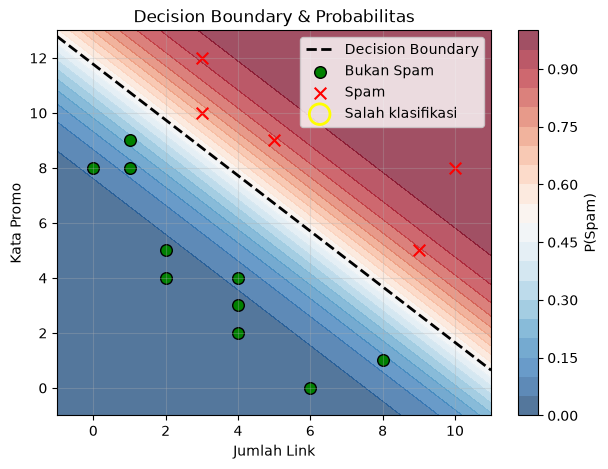

In [ ]:
# Jawaban B4
x_min, x_max = X[:,0].min()-1, X[:,0].max()+1
y_min, y_max = X[:,1].min()-1, X[:,1].max()+1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
probs = log_reg.predict_proba(grid).reshape(xx.shape)

plt.figure(figsize=(7,5))
plt.contourf(xx, yy, probs, levels=20, cmap="RdBu_r", alpha=0.7)
plt.colorbar(label="P(Spam)")
xs = np.linspace(x_min, x_max, 100)
ys = -(b0 + b1*xs) / b2   # z = 0
plt.plot(xs, ys, "k--", lw=2, label="Decision Boundary")

for label, color, mark in [(0,"green","o"), (1,"red","x")]:
    m = y_test == label
    plt.scatter(X_test[m,0], X_test[m,1], c=color, marker=mark,
                edgecolor="k", s=70,
                label="Bukan Spam" if label==0 else "Spam")

wrong = y_test != y_pred
plt.scatter(X_test[wrong,0], X_test[wrong,1], s=220,
            facecolors="none", edgecolors="yellow", linewidth=2,
            label="Salah klasifikasi")
plt.xlabel("Jumlah Link"); plt.ylabel("Kata Promo")
plt.title("Decision Boundary & Probabilitas"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

**Jawaban B4 (analisis):**

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [ ]:
# Jawaban B5
proba = log_reg.predict_proba(X_test)
rows = []
for t in [0.3, 0.5, 0.7]:
    yp = (proba >= t).astype(int)
    cm = confusion_matrix(y_test, yp)
    rows.append({
        "Threshold": t,
        "TN": cm[0,0], "FP": cm[0,1], "FN": cm[1,0], "TP": cm[1,1],
        "Precision": precision_score(y_test, yp),
        "Recall":    recall_score(y_test, yp),
        "F1":        f1_score(y_test, yp),
    })
print(pd.DataFrame(rows).to_string(index=False, float_format="%.3f"))

 Threshold  TN  FP  FN  TP  Precision  Recall    F1
     0.300  10   0   0   5      1.000   1.000 1.000
     0.500  10   0   0   5      1.000   1.000 1.000
     0.700  10   0   0   5      1.000   1.000 1.000


**Jawaban B5 (analisis):**

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [ ]:
# Jawaban B6
email_baru = np.array([[1,2],[5,6],[9,10],[2,11]])
proba_baru = log_reg.predict_proba(email_baru)
THRESHOLD = 0.3   # pilihan dari B5

print(f"Threshold dipakai: {THRESHOLD}\n")
for i, (x, p) in enumerate(zip(email_baru, proba_baru), 1):
    label = "Spam" if p >= THRESHOLD else "Bukan Spam"
    print(f"E{i}: link={x[0]}, promo={x[1]:>2} -> P(Spam)={p:.4f} -> {label}")

Threshold dipakai: 0.3

E1: link=1, promo= 2 -> P(Spam)=0.0020 -> Bukan Spam
E2: link=5, promo= 6 -> P(Spam)=0.3763 -> Spam
E3: link=9, promo=10 -> P(Spam)=0.9944 -> Spam
E4: link=2, promo=11 -> P(Spam)=0.7080 -> Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**

**Jawaban C2:**

**Jawaban C3:**

**Jawaban C4:**

**Jawaban C5:**

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [ ]:
# Jawaban Bonus (Perbaikan)
from sklearn.linear_model import LinearRegression as SKLinReg
from sklearn.linear_model import LogisticRegression as SKLogReg
from sklearn.metrics import r2_score as sk_r2, accuracy_score as sk_acc

# --- 1. Linear Regression (Muat ulang data Ads) ---
df_ads = pd.read_csv("Ads_Data.csv")
X_ads = df_ads[["BiayaIklan"]].values.astype(float)
y_ads = df_ads["Penjualan"].values.astype(float)

# Split data Ads
X_train_ads, X_test_ads, y_train_ads, y_test_ads = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE)

# Latih ulang model manual Linear Regression
lin_reg_ads = LinearRegression().fit(X_train_ads, y_train_ads)
yp_te_ads = lin_reg_ads.predict(X_test_ads)

# Latih model sklearn
sk_lin = SKLinReg().fit(X_train_ads, y_train_ads)

print("== Linear Regression (Ads Data) ==")
print(f"Sendiri : b0={lin_reg_ads.intercept_:.4f}, b1={lin_reg_ads.coef_[0]:.4f}")
print(f"sklearn : b0={sk_lin.intercept_:.4f}, b1={sk_lin.coef_[0]:.4f}")
print(f"R2 test sendiri : {r2_score(y_test_ads, yp_te_ads):.4f}")
print(f"R2 test sklearn : {sk_r2(y_test_ads, sk_lin.predict(X_test_ads)):.4f}")

# --- 2. Logistic Regression (Pakai data Email yang sudah ada) ---
# Latih ulang model manual Logistic Regression
log_reg_email = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(X_train, y_train)
y_pred_email = log_reg_email.predict(X_test)

# Latih model sklearn
sk_log = SKLogReg(max_iter=5000).fit(X_train, y_train)

print("\n== Logistic Regression (Email Data) ==")
print(f"Sendiri : b0={log_reg_email.intercept_:.4f}, coef={log_reg_email.coef_}")
print(f"sklearn : b0={sk_log.intercept_[0]:.4f}, coef={sk_log.coef_[0]}")
print(f"Akurasi sendiri : {accuracy_score(y_test, y_pred_email):.4f}")
print(f"Akurasi sklearn : {sk_acc(y_test, sk_log.predict(X_test)):.4f}")

== Linear Regression (Ads Data) ==
Sendiri : b0=27.7936, b1=9.1971
sklearn : b0=27.7936, b1=9.1971
R2 test sendiri : 0.9547
R2 test sklearn : 0.9547

== Logistic Regression (Email Data) ==
Sendiri : b0=-8.3285, coef=[0.71553544 0.70756566]
sklearn : b0=-7.7304, coef=[0.6580422  0.65927523]
Akurasi sendiri : 1.0000
Akurasi sklearn : 1.0000


**Jawaban Bonus (analisis):**

In [ ]:
!pip install scikit-learn


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
